In [1]:
pip install streamlit pandas numpy matplotlib seaborn scikit-learn wordcloud

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [4]:
# Load data dari CSV
df = pd.read_csv(r'D:\Analisis sentimen menggunakan Neural Network\tweet_data_kebakaran_hutan.csv')
print("Jumlah data:", len(df))
df.head()

Jumlah data: 380


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username
0,2117251599404003646,2026-11-02T13:44:52.000Z,322,"🚨🚨ALERTA ALERTA TEMAN-TEMAN \n\nJATIM, tepatny...",2117251599404003646,https://pbs.twimg.com/amplify_video_thumb/2117...,NaN,in,NaN,1,3,259,https://x.com/jenostalker/status/2117251599404...,1885318915498401796,jenostalker
1,2113108778526843359,2026-10-22T03:22:47.000Z,5353,"Aries Sutio, relawan pemadam kebakaran hutan d...",2113108778526843359,https://pbs.twimg.com/amplify_video_thumb/2113...,NaN,in,NaN,82,87,2504,https://x.com/BBCIndonesia/status/211310877852...,23772644,BBCIndonesia
2,2117612377504112928,2026-11-03T13:38:28.000Z,127,"KARHUTLA DI INDONESIA\nPERUSAHAAN UNTUNG, RAKY...",2117612377504112928,https://pbs.twimg.com/amplify_video_thumb/2117...,NaN,in,NaN,1,77,22,https://x.com/AganFakta1/status/21176123775041...,2100793540486057984,AganFakta1
3,2117228223574782370,2026-11-02T12:11:59.000Z,688,Update Kebakaran hutan dan lahan‼️ \nMalam ini...,2117228223574782370,https://pbs.twimg.com/amplify_video_thumb/2117...,NaN,in,NaN,3,6,542,https://x.com/jenostalker/status/2117228223574...,1885318915498401796,jenostalker
4,2117566110400913821,2026-11-03T10:34:37.000Z,343,🚨🚨 KALIMANTAN TIMUR GUYS\n\nSore tadi di Desa ...,2117566110400913821,https://pbs.twimg.com/amplify_video_thumb/2117...,NaN,in,NaN,3,1,287,https://x.com/jenostalker/status/2117566110400...,1885318915498401796,jenostalker


In [5]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['full_text'].apply(clean_text)
df[['full_text', 'clean_text']].head()

,full_text,clean_text
0,"🚨🚨ALERTA ALERTA TEMAN-TEMAN \n\nJATIM, tepatny...",alerta alerta teman teman jatim tepatnya di jl...
1,"Aries Sutio, relawan pemadam kebakaran hutan d...",aries sutio relawan pemadam kebakaran hutan da...
2,"KARHUTLA DI INDONESIA\nPERUSAHAAN UNTUNG, RAKY...",karhutla di indonesia perusahaan untung rakyat...
3,Update Kebakaran hutan dan lahan‼️ \nMalam ini...,update kebakaran hutan dan lahan malam ini nov...
4,🚨🚨 KALIMANTAN TIMUR GUYS\n\nSore tadi di Desa ...,kalimantan timur guys sore tadi di desa sempat...


In [6]:
positif_words = ['aman', 'lega', 'selamat', 'bantuan', 'pulih', 'padam', 'berhasil', 'terkendali', 'semangat', 'apresiasi', 'dukungan', 'donasi', 'tanggap', 'pahlawan', 'relawan', 'evakuasi', 'baik']
negatif_words = ['banjir', 'parah', 'rusak', 'macet', 'bahaya', 'kebakaran', 'bencana', 'darurat', 'korban', 'asap', 'membara', 'terbakar', 'api', 'krisis', 'ancaman', 'duka', 'mati', 'rugi', 'tewas', 'sesak', 'racun', 'boikot', 'penyebab', 'hukum']

def label_sentiment(text):
    words = text.split()
    pos_count = sum(1 for w in words if w in positif_words)
    neg_count = sum(1 for w in words if w in negatif_words)
    
    if pos_count > neg_count:
        return 'positif'
    elif neg_count > pos_count:
        return 'negatif'
    else:
        return 'netral'

df['sentimen'] = df['clean_text'].apply(label_sentiment)
df['sentimen'].value_counts()

sentimen
negatif    313
netral      56
positif     11
Name: count, dtype: int64

C:\Users\user\AppData\Local\Temp\ipykernel_20296\2684617662.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=axes[0])


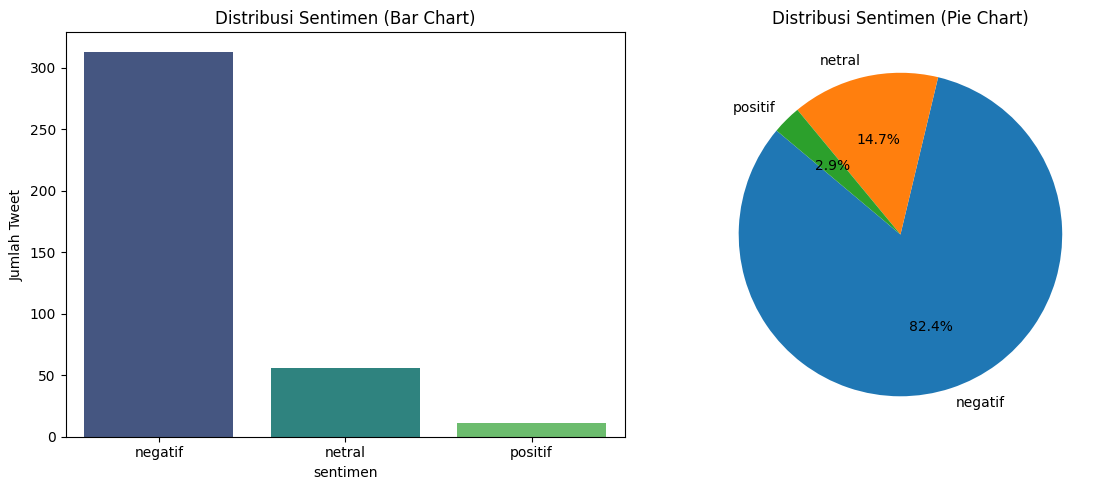

In [7]:
counts = df['sentimen'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar Chart
sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=axes[0])
axes[0].set_title('Distribusi Sentimen (Bar Chart)')
axes[0].set_ylabel('Jumlah Tweet')

# Pie Chart
axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=140)
axes[1].set_title('Distribusi Sentimen (Pie Chart)')

plt.tight_layout()
plt.show()

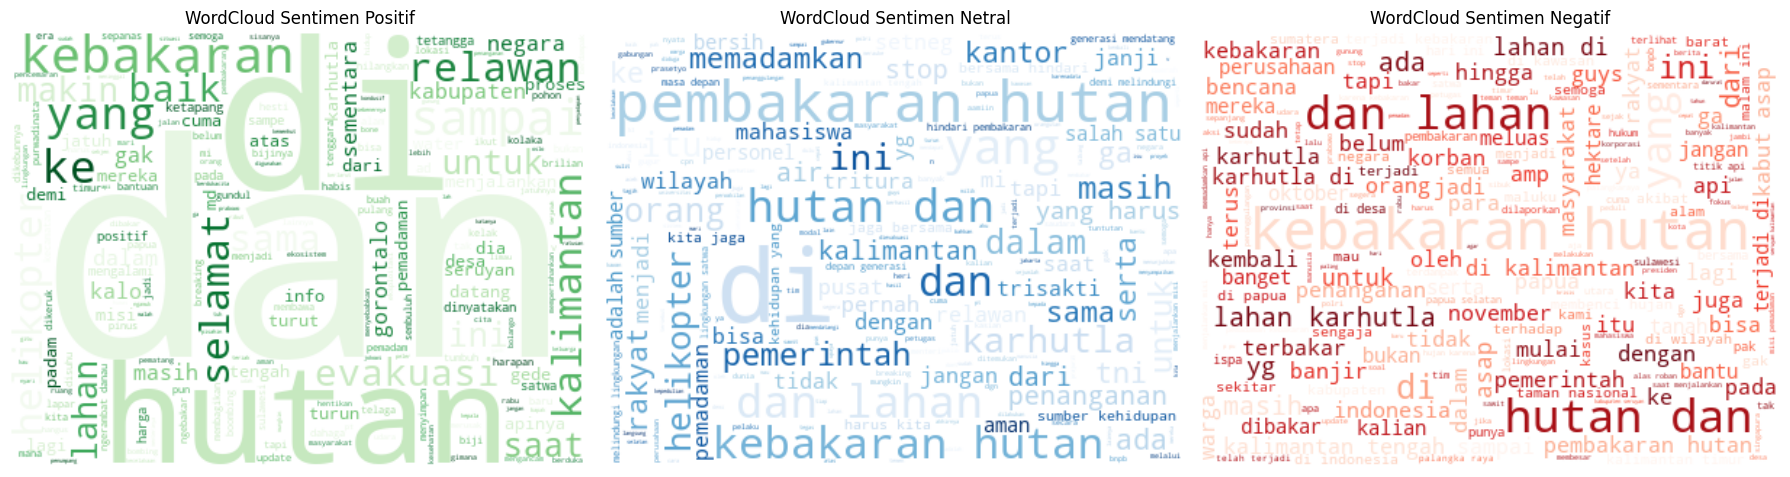

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sentimens = ['positif', 'netral', 'negatif']
colormaps = ['Greens', 'Blues', 'Reds']

for i, s in enumerate(sentimens):
    text = " ".join(df[df['sentimen'] == s]['clean_text'])
    if text.strip():
        wc = WordCloud(width=400, height=300, background_color='white', colormap=colormaps[i]).generate(text)
        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f'WordCloud Sentimen {s.capitalize()}')
        axes[i].axis('off')

plt.tight_layout()
plt.show()

In [9]:
# Train Test Split (80:20)
X = df['clean_text']
y = df['sentimen']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=1000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Neural Network MLP
mlp = MLPClassifier(hidden_layer_sizes=(100,), activation='relu', solver='adam', max_iter=300, random_state=42)
mlp.fit(X_train_tfidf, y_train)

# Prediksi
y_pred = mlp.predict(X_test_tfidf)
print("Model berhasil dilatih!")

Model berhasil dilatih!


--- Classification Report ---
              precision    recall  f1-score   support

     negatif       0.88      0.97      0.92        63
      netral       0.71      0.45      0.56        11
     positif       0.00      0.00      0.00         2

    accuracy                           0.87        76
   macro avg       0.53      0.47      0.49        76
weighted avg       0.84      0.87      0.85        76



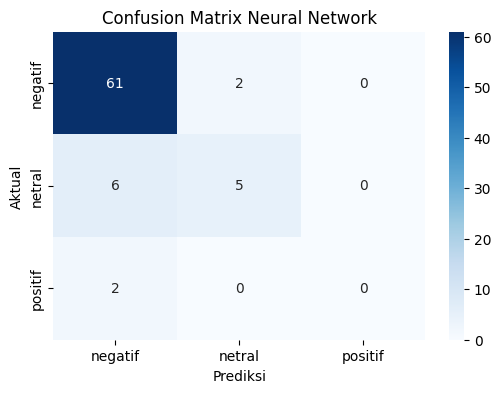

In [10]:
# Classification Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
labels = sorted(list(set(y_test)))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix Neural Network')
plt.show()

In [13]:
teks_baru = "dia sebenarnya bisa, tetapi malas."

# Pembersihan & Vektorisasi
teks_clean = clean_text(teks_baru)
teks_vec = vectorizer.transform([teks_clean])

# Prediksi
prediksi = mlp.predict(teks_vec)[0]
probabilitas = mlp.predict_proba(teks_vec)[0]

emoji_dict = {'positif': '😊 Positif', 'netral': '😐 Netral', 'negatif': '😡 Negatif'}

print("Teks Asli :", teks_baru)
print("Hasil Prediksi:", emoji_dict.get(prediksi, prediksi))
print("\nProbabilitas:")
for cls, prob in zip(mlp.classes_, probabilitas):
    print(f"- {cls}: {prob*100:.2f}%")

Teks Asli : dia sebenarnya bisa, tetapi malas.
Hasil Prediksi: 😡 Negatif

Probabilitas:
- negatif: 79.66%
- netral: 9.54%
- positif: 10.80%


In [14]:
import pandas as pd
import re

# 1. Load Data
df = pd.read_csv(r'D:\Analisis sentimen menggunakan Neural Network\tweet_data_kebakaran_hutan.csv')

# 2. Fungsi Cleansing
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# 3. Terapkan Cleansing & Pelabelan
df['clean_text'] = df['full_text'].apply(clean_text)

positif_words = ['aman', 'lega', 'selamat', 'bantuan', 'pulih', 'padam', 'berhasil', 'terkendali', 'semangat', 'apresiasi', 'dukungan', 'donasi', 'tanggap', 'pahlawan', 'relawan', 'evakuasi', 'baik']
negatif_words = ['banjir', 'parah', 'rusak', 'macet', 'bahaya', 'kebakaran', 'bencana', 'darurat', 'korban', 'asap', 'membara', 'terbakar', 'api', 'krisis', 'ancaman', 'duka', 'mati', 'rugi', 'tewas', 'sesak', 'racun', 'boikot', 'penyebab', 'hukum']

def label_sentiment(text):
    words = text.split()
    pos_count = sum(1 for w in words if w in positif_words)
    neg_count = sum(1 for w in words if w in negatif_words)
    
    if pos_count > neg_count:
        return 'positif'
    elif neg_count > pos_count:
        return 'negatif'
    else:
        return 'netral'

df['sentimen'] = df['clean_text'].apply(label_sentiment)

# 4. SIMPAN KE CSV
df.to_csv('Alma_Test4_Analisis Sentimen.csv', index=False)
print("Pembersihan selesai dan file berhasil disimpan!")

Pembersihan selesai dan file berhasil disimpan!
